In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [ ]:
df = pd.read_csv('superstore_orders.csv')
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [3]:
df.shape

(10194, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

### Build a monthly series

In [6]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly.index = monthly.index.to_timestamp()
monthly.head(12)

Order Date
2023-01-01    14518.0550
2023-02-01     4519.8920
2023-03-01    56933.9090
2023-04-01    28295.3450
2023-05-01    26319.7670
2023-06-01    34669.4796
2023-07-01    33946.3930
2023-08-01    28918.3385
2023-09-01    82670.4288
2023-10-01    32413.3390
2023-11-01    78826.9567
2023-12-01    72008.3085
Freq: MS, Name: Sales, dtype: float64

### Plot the series

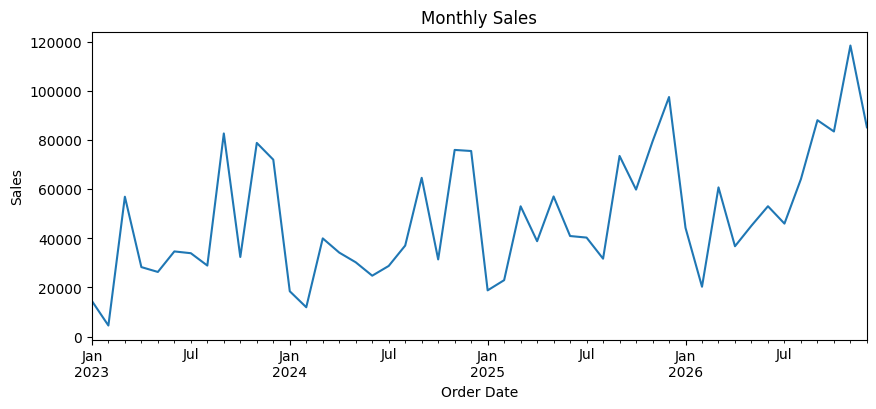

In [7]:
monthly.plot(figsize=(10,4), title='Monthly Sales')
plt.ylabel('Sales')
plt.show()

### Fit the Holt-Winters Model

In [9]:
model = ExponentialSmoothing(monthly, trend='add',
                             seasonal='add', seasonal_periods=12).fit()

### Forecast for next 6 months

In [16]:
forecast = model.forecast(6)
forecast

2027-01-01    51139.854692
2027-02-01    43083.290971
2027-03-01    77512.393896
2027-04-01    62985.236524
2027-05-01    70405.368325
2027-06-01    67039.664057
Freq: MS, dtype: float64

### Plot history and foreccast together

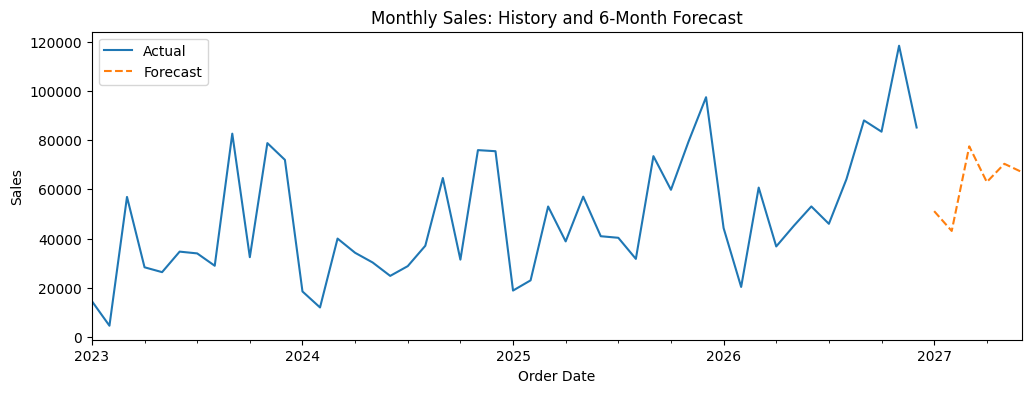

In [20]:
plt.figure(figsize=(12,4))
plt.title('Monthly Sales: History and 6-Month Forecast')
monthly.plot(label='Actual')
forecast.plot(label='Forecast', style='--')
plt.ylabel('Sales')
plt.legend()
plt.show()

### Check the Accuracy

In [21]:
train = monthly.iloc[:-6]
test  = monthly.iloc[-6:]

m2 = ExponentialSmoothing(train, trend='add', seasonal='add',
                          seasonal_periods=12).fit()
pred = m2.forecast(6)

mape = (abs(test - pred) / test).mean() * 100
print('MAPE:', round(mape, 1), '%')

MAPE: 16.1 %
